In [1]:
import sys
from pathlib import Path

root = Path.cwd().resolve()
if root.name == "notebook":
    root = root.parent

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

d:\Anaconda\envs\customer\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Max_Depth,Fidelity_Accuracy_Mean_Pct,Fidelity_Accuracy_Std_Pct,Macro_F1,Avg_Leaf_Nodes
0,3,85.347222,0.941990,0.855375,8
1,4,87.060185,1.312318,0.872571,16
2,5,89.305556,0.921866,0.892387,28
3,6,90.138889,1.270831,0.899601,43


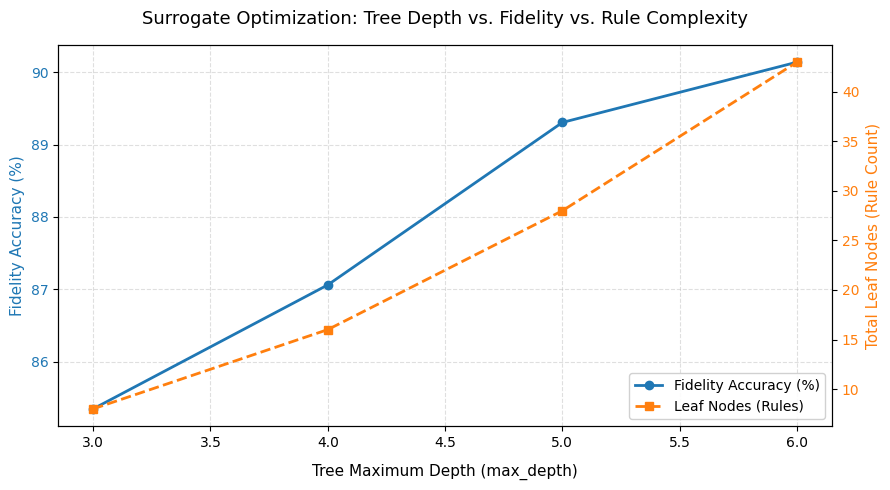

Surrogate Fidelity (Accuracy): 87.06% | Macro F1: 0.8729


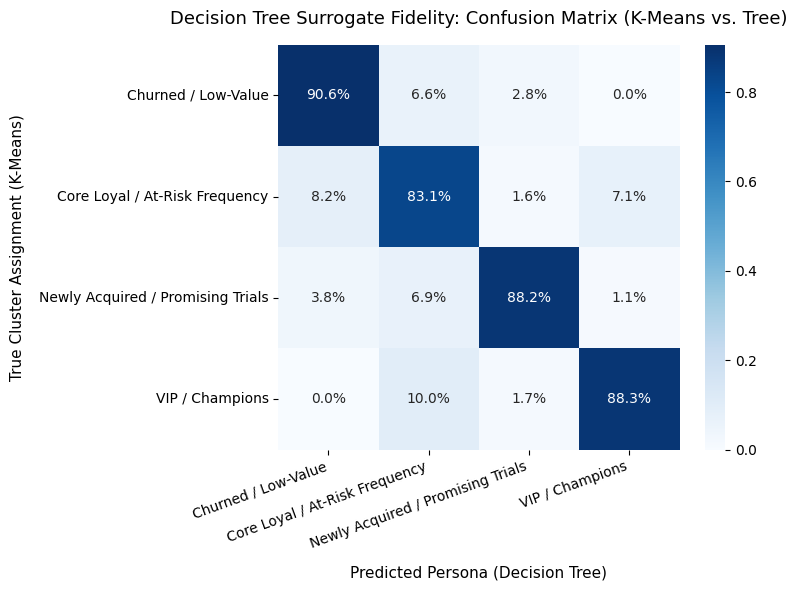

,Feature,Importance,Importance_Share_Pct
0,NetSpending,0.386619,38.661859
1,PurchaseVelocity_Monthly,0.221440,22.144014
2,CustomerTenureDays,0.204535,20.453484
3,Frequency,0.095865,9.586511
4,Recency,0.052293,5.229313
5,NumDistinctProducts,0.037869,3.786895
6,AvgOrderValue,0.001379,0.137924
7,ReturnRate,0.000000,0.000000


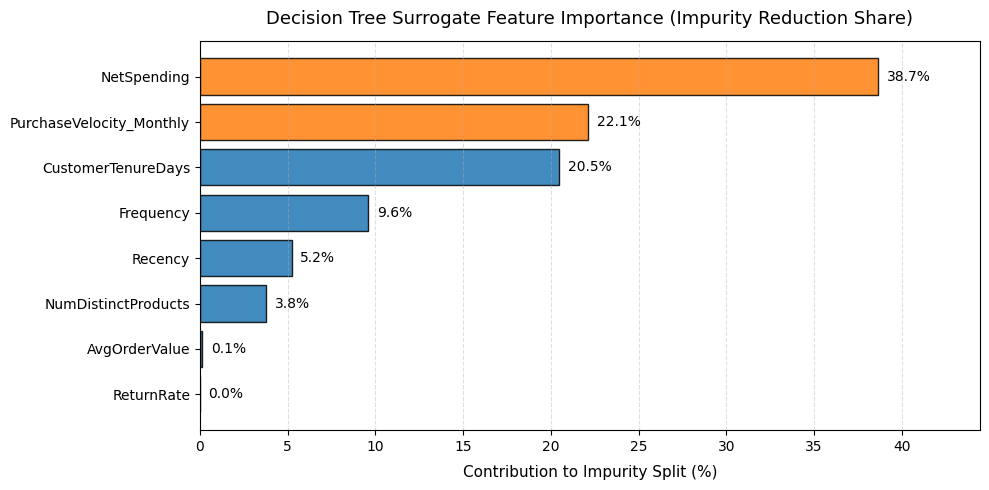

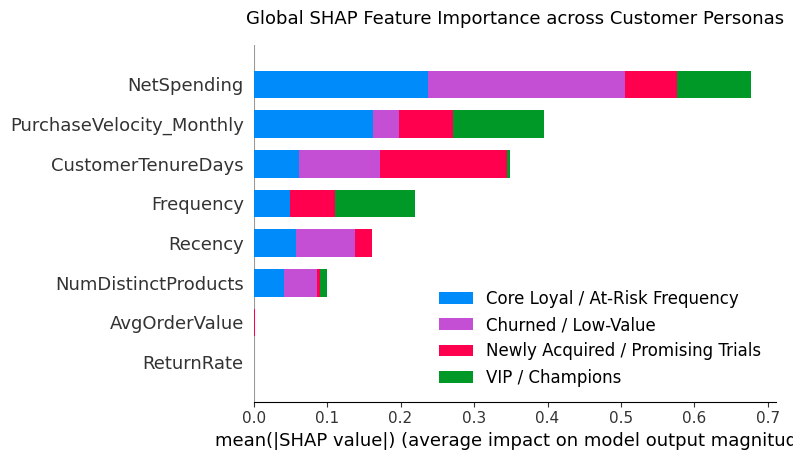

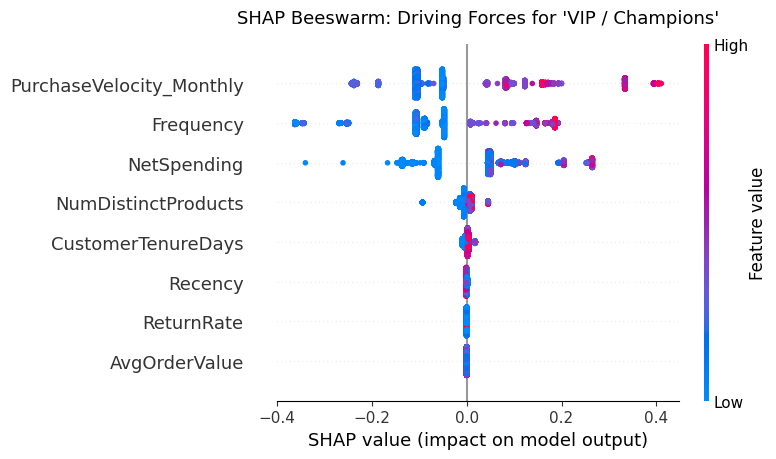

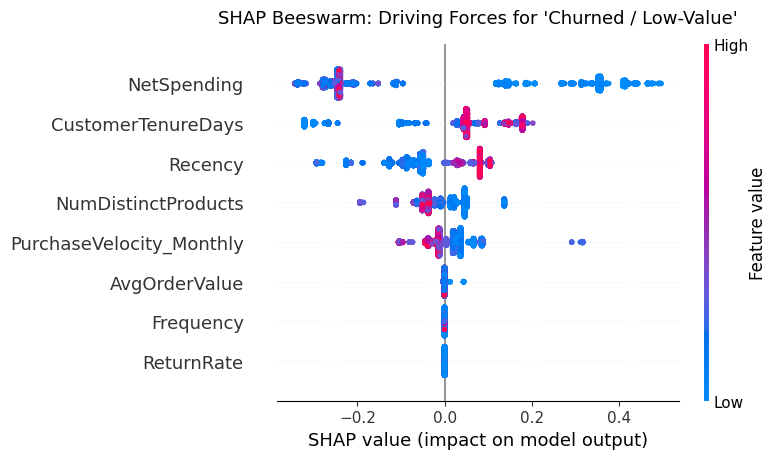

Rule Fidelity vs. K-Means: 88.29% | Total Rules: 16


,Rule_ID,Cluster,Persona,Confidence_Pct,Sample_Support,Conditions_Count,Logic_Conditions
0,Rule_01,0,Churned / Low-Value,99.27,959,4,NetSpending <= 521.52 AND CustomerTenureDays >...
1,Rule_02,0,Churned / Low-Value,93.33,30,4,NetSpending <= 521.52 AND CustomerTenureDays <...
2,Rule_03,0,Churned / Low-Value,66.67,45,4,NetSpending <= 521.52 AND CustomerTenureDays >...
3,Rule_04,0,Churned / Low-Value,57.95,195,4,NetSpending <= 521.52 AND CustomerTenureDays >...
4,Rule_05,1,Core Loyal / At-Risk Frequency,97.81,822,4,NetSpending > 521.52 AND PurchaseVelocity_Mont...
5,Rule_06,1,Core Loyal / At-Risk Frequency,88.30,265,4,NetSpending > 521.52 AND PurchaseVelocity_Mont...
6,Rule_07,1,Core Loyal / At-Risk Frequency,71.72,99,4,NetSpending > 521.52 AND PurchaseVelocity_Mont...
7,Rule_08,1,Core Loyal / At-Risk Frequency,66.90,142,4,NetSpending > 521.52 AND PurchaseVelocity_Mont...
8,Rule_09,1,Core Loyal / At-Risk Frequency,60.49,205,4,NetSpending > 521.52 AND PurchaseVelocity_Mont...
9,Rule_10,2,Newly Acquired / Promising Trials,100.00,412,4,NetSpending <= 521.52 AND CustomerTenureDays <...


-- ====================================================================
-- Auto-generated Decision Tree Rules from Customer Segmentation
-- Source Model: DecisionTreeClassifier (Depth=4)
-- ====================================================================
SELECT
    CustomerID,
    CASE
        -- Confidence: 100.0%, Support: 412 accounts
        WHEN NetSpending <= 521.52 AND CustomerTenureDays <= 75.50 AND PurchaseVelocity_Monthly > 0.55 AND AvgOrderValue > 68.76 THEN 'Newly Acquired / Promising Trials'
        -- Confidence: 99.3%, Support: 959 accounts
        WHEN NetSpending <= 521.52 AND CustomerTenureDays > 75.50 AND Recency > 80.50 AND NumDistinctProducts <= 55.50 THEN 'Churned / Low-Value'
        -- Confidence: 97.8%, Support: 822 accounts
        WHEN NetSpending > 521.52 AND PurchaseVelocity_Monthly <= 0.66 AND NumDistinctProducts > 36.50 AND Frequency <= 5.50 THEN 'Core Loyal / At-Risk Frequency'
        -- Confidence: 96.3%, Support: 464 accounts
        WHEN NetSpend

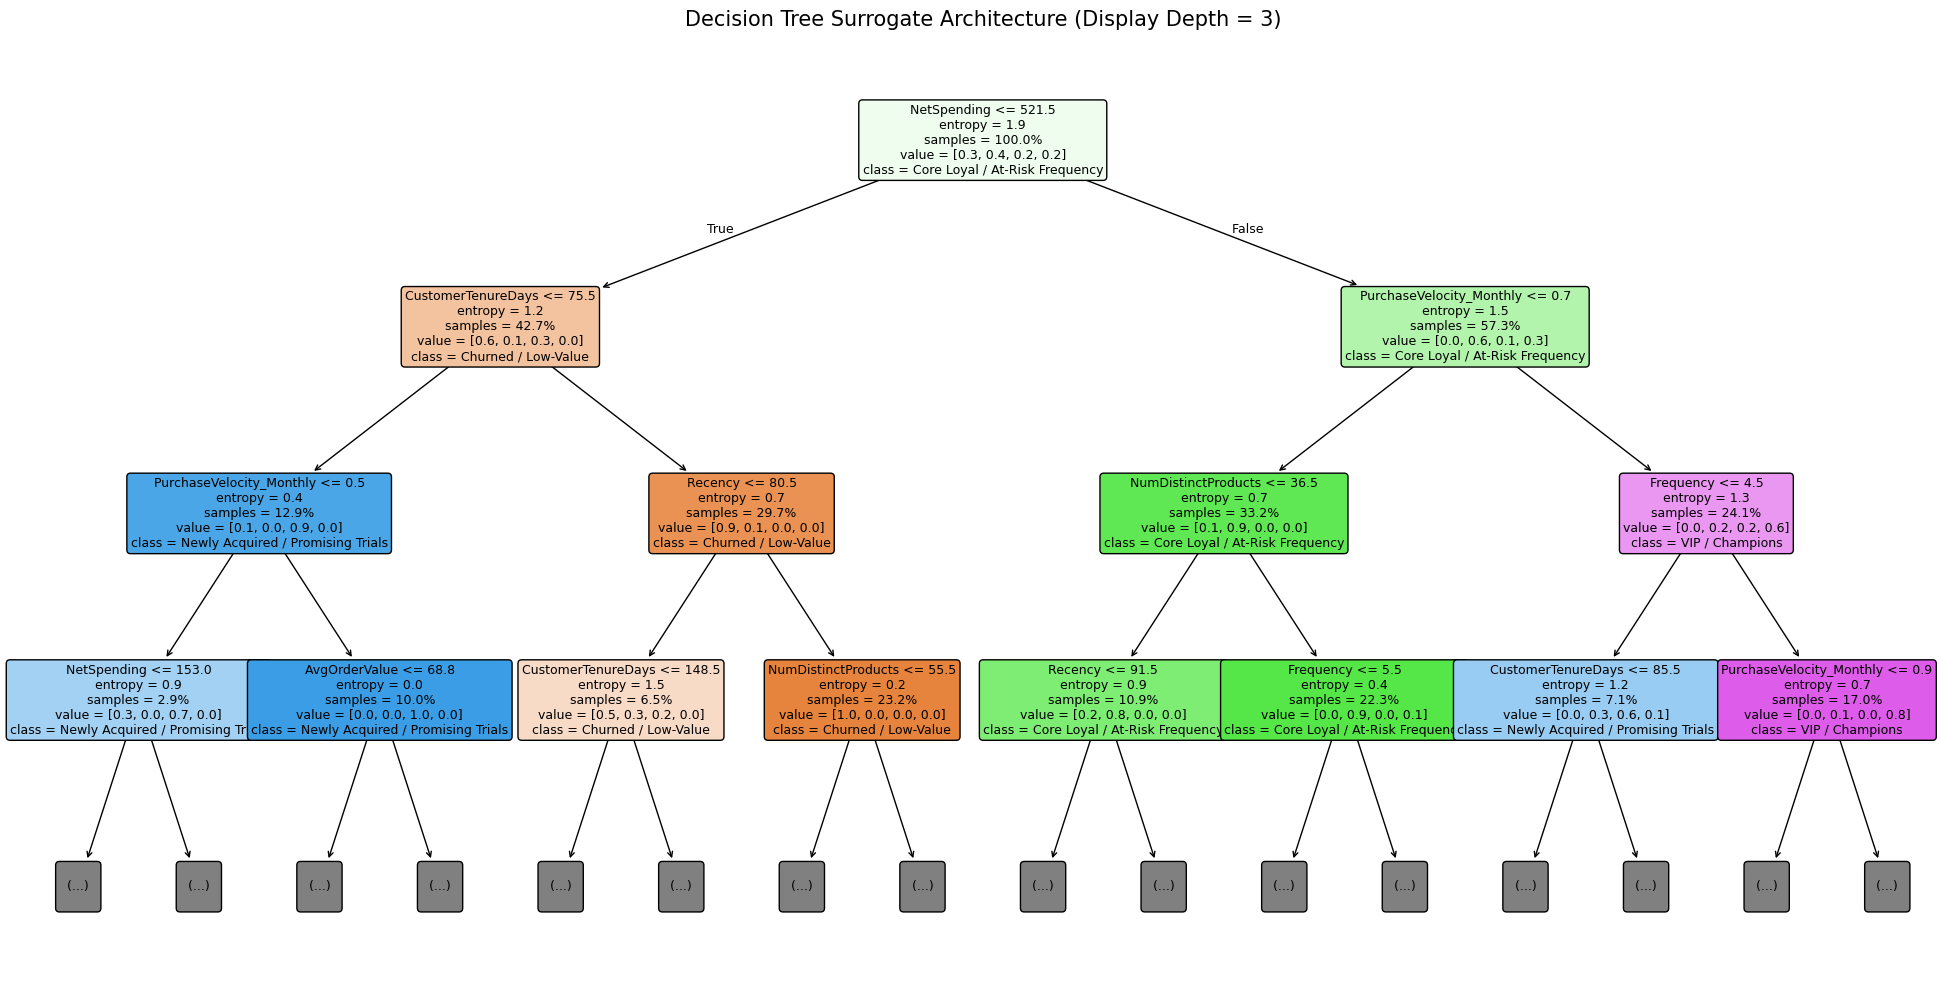

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from src.surrogate import (
    DecisionTreeSurrogateModel,
    SurrogateSHAPExplainer,
    DecisionTreeRuleExtractor,
    plot_surrogate_confusion_matrix,
    plot_depth_tuning_curve,
    plot_feature_importance_bar,
    plot_decision_tree_diagram,
    plot_shap_summary_multiclass,
    plot_shap_cohort_beeswarm,
)

# 1. Nạp dữ liệu khách hàng unscaled
df = pd.read_parquet('../data/clustered/customer_segmented.parquet')
features = [
    "Recency", "Frequency", "NetSpending", "AvgOrderValue",
    "NumDistinctProducts", "CustomerTenureDays", "PurchaseVelocity_Monthly", "ReturnRate"
]
X = df[features]
y = df["Cluster"]

personas = {
    0: "Churned / Low-Value",
    1: "Core Loyal / At-Risk Frequency",
    2: "Newly Acquired / Promising Trials",
    3: "VIP / Champions",
}
persona_list = [personas[i] for i in range(4)]

# Surrogate model
trainer = DecisionTreeSurrogateModel(min_samples_leaf=20, criterion="entropy")

# Khảo sát độ sâu 3, 4, 5, 6
depth_table = trainer.evaluate_depth_candidates(X, y, depth_candidates=[3, 4, 5, 6])
display(depth_table)

fig_tuning = plot_depth_tuning_curve(depth_table)
plt.show()

# Chọn max_depth = 4 (Fidelity ~87%, 16 lá / 16 luật chuẩn)
trainer.max_depth = 4
cv_metrics = trainer.cross_validation(X, y, n_splits=5, class_names=personas)
print(f"Surrogate Fidelity (Accuracy): {cv_metrics['overall_fidelity']*100:.2f}% | Macro F1: {cv_metrics['macro_f1']:.4f}")

fig_cm = plot_surrogate_confusion_matrix(cv_metrics["confusion_matrix"], persona_list)
plt.show()

# Khớp cây trên toàn bộ tập dữ liệu
trainer.fit(X, y, class_names=personas)
df_imp = trainer.get_feature_importance()
display(df_imp)

fig_imp = plot_feature_importance_bar(df_imp)
plt.show()

# XAI and SHAP
explainer = SurrogateSHAPExplainer(trainer.model, feature_names=features, class_names=personas)
shap_values = explainer.fit_transform(X)

# SHAP
fig_shap = plot_shap_summary_multiclass(shap_values, X, persona_list)
plt.show()

# Beeswarm from VIP customers
fig_vip = plot_shap_cohort_beeswarm(shap_values, X, class_idx=3, class_name="VIP / Champions")
plt.show()

# Biểu đồ Beeswarm cho nhóm Rời bỏ (Cluster 0)
fig_churn = plot_shap_cohort_beeswarm(shap_values, X, class_idx=0, class_name="Churned / Low-Value")
plt.show()

# Rule
rule_extractor = DecisionTreeRuleExtractor(trainer.model, feature_names=features, class_names=personas) # type: ignore
rule_audit = rule_extractor.evaluate_rule_fidelity(X, y)
print(f"Rule Fidelity vs. K-Means: {rule_audit['rule_fidelity']*100:.2f}% | Total Rules: {rule_audit['total_rules']}")
df_rules = rule_extractor.get_rules_summary_dataframe()
display(df_rules)

# SQL CASE - WHEN
sql_query = rule_extractor.to_sql_case_when(table_name="online_retail_customer_features")
print(sql_query)

# Tree structure
fig_tree = plot_decision_tree_diagram(trainer.model, features, persona_list, max_depth=3)
plt.show()